# Intelligent Online Retail Customer Segmentation & Marketing Recommendation System
### Big Data Analytics mini-project · Apache Spark (PySpark) · UCI Online Retail II

**Business question:** *Who are our customers, how valuable are they, who is at risk of leaving, and what action
should the business take for each customer?*

This notebook walks through the pipeline stage by stage. Every stage calls the same module in `src/` that the
production pipeline (`python -m src.pipeline`) uses.

## 1. Introduction
An online gift retailer based in the UK records about 1 million invoice lines over two years. The raw
transactions don't tell the business which customers matter, which are slipping away, or how to target each group.

## 2. Problem statement
Turn raw transaction logs into **actionable, per-customer intelligence**:
- a segment
- a value score
- a churn risk
- a recommended marketing action
- product recommendations

The processing has to scale beyond a single machine.

## 3. Objectives
1. Build a scalable ingestion and cleaning pipeline in PySpark, with data-quality tracking.
2. Analyse revenue, products, countries and time trends with Spark SQL.
3. Engineer RFM plus behavioural customer features using aggregations and window functions.
4. Segment customers with MLlib K-Means, choosing K with silhouette analysis.
5. Score customer value and churn risk, then generate rule-based marketing actions.
6. Mine product associations with FP-Growth for cross-sell recommendations.
7. Present the results in a dashboard and business insights.

## 4. Technologies used

| Technology | Purpose |
|---|---|
| PySpark 4 (DataFrame, Spark SQL) | distributed processing |
| Spark MLlib | K-Means, PCA, FP-Growth, StandardScaler |
| Parquet | columnar storage (bronze / silver / gold layers) |
| pandas, Matplotlib, Plotly | reporting |
| Streamlit | dashboard |

## 5–7. Libraries and Spark initialisation

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from pyspark.sql import functions as F
from IPython.display import Image, display

from src import (config, ingestion, cleaning, eda, features, clustering, profiling, scoring,
                 basket, product_behaviour, recommender, visualization)
from src.pipeline import save_final
from src.spark_session import get_spark

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
spark = get_spark()
print("Spark", spark.version, "| master:", spark.sparkContext.master,
      "| default parallelism:", spark.sparkContext.defaultParallelism)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/06 12:58:44 WARN Utils: Your hostname, rohits-MacBook-Air.local, resolves to a loopback address: 127.0.0.1; using 10.87.127.203 instead (on interface en0)
26/10/06 12:58:44 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/06 12:58:45 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | master: local[*] | default parallelism: 10


## 8. Load the dataset
The dataset is **UCI Online Retail II** (id 502). `scripts/download_data.py` converts its two Excel sheets into one
CSV. Spark then reads that CSV with an **explicit schema**, which is faster and safer than `inferSchema`, and
stores it as Parquet (the *bronze* layer).

In [2]:
bronze = ingestion.ingest(spark)
bronze.printSchema()
print(f"Raw rows: {bronze.count():,}")
bronze.show(5, truncate=False)

root
 |-- Invoice: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: timestamp (nullable = true)
 |-- Price: double (nullable = true)
 |-- Country: string (nullable = true)
 |-- CustomerID: integer (nullable = true)



Raw rows: 1,067,371


+-------+---------+-----------------------------------+--------+-------------------+-----+--------------+----------+
|Invoice|StockCode|Description                        |Quantity|InvoiceDate        |Price|Country       |CustomerID|
+-------+---------+-----------------------------------+--------+-------------------+-----+--------------+----------+
|489434 |85048    |15CM CHRISTMAS GLASS BALL 20 LIGHTS|12      |2009-12-01 07:45:00|6.95 |United Kingdom|13085     |
|489434 |79323P   |PINK CHERRY LIGHTS                 |12      |2009-12-01 07:45:00|6.75 |United Kingdom|13085     |
|489434 |79323W   | WHITE CHERRY LIGHTS               |12      |2009-12-01 07:45:00|6.75 |United Kingdom|13085     |
|489434 |22041    |RECORD FRAME 7" SINGLE SIZE        |48      |2009-12-01 07:45:00|2.1  |United Kingdom|13085     |
|489434 |21232    |STRAWBERRY CERAMIC TRINKET BOX     |24      |2009-12-01 07:45:00|1.25 |United Kingdom|13085     |
+-------+---------+-----------------------------------+--------+

## 9. Data understanding

In [3]:
bronze.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in bronze.columns]).show()
bronze.describe("Quantity", "Price").show()
print("Cancelled invoice lines:", bronze.filter(F.col("Invoice").startswith("C")).count())

+-------+---------+-----------+--------+-----------+-----+-------+----------+
|Invoice|StockCode|Description|Quantity|InvoiceDate|Price|Country|CustomerID|
+-------+---------+-----------+--------+-----------+-----+-------+----------+
|      0|        0|       4382|       0|          0|    0|      0|    243007|
+-------+---------+-----------+--------+-----------+-----+-------+----------+



+-------+------------------+------------------+
|summary|          Quantity|             Price|
+-------+------------------+------------------+
|  count|           1067371|           1067371|
|   mean|   9.9388984711033| 4.649387727429348|
| stddev|172.70579407675038|123.55305872146526|
|    min|            -80995|         -53594.36|
|    max|             80995|           38970.0|
+-------+------------------+------------------+



Cancelled invoice lines: 19494


## 10. Data cleaning
| Rule | Why |
|---|---|
| Drop rows with a null `CustomerID` | Customer-level analysis needs to know who bought. |
| Set aside cancellations (`Invoice` starting with `C`) | They become the *cancellation-rate* feature. |
| Keep only `Quantity > 0` and `Price > 0` | Removes returns, adjustments and free items. |
| Drop non-product stock codes (POST, M, BANK CHARGES, AMAZONFEE, TEST…) | These are fees, not purchases. |
| Remove duplicates | Duplicates include the December 2010 rows that appear in both sheets. |

The *silver* layer is Parquet partitioned by `Year` and `Month`.

In [4]:
tx, cancelled, dq = cleaning.run(spark, bronze)
tx = tx.cache()
pd.DataFrame(dq)

,step,rows,removed
0,raw,1067371,0
1,customer_id_present,824364,243007
2,not_cancelled,805620,261751
3,positive_quantity_price,805549,261822
4,product_codes_only,802632,264739
5,deduplicated,776577,290794
6,reversed_orders_removed,770417,296954


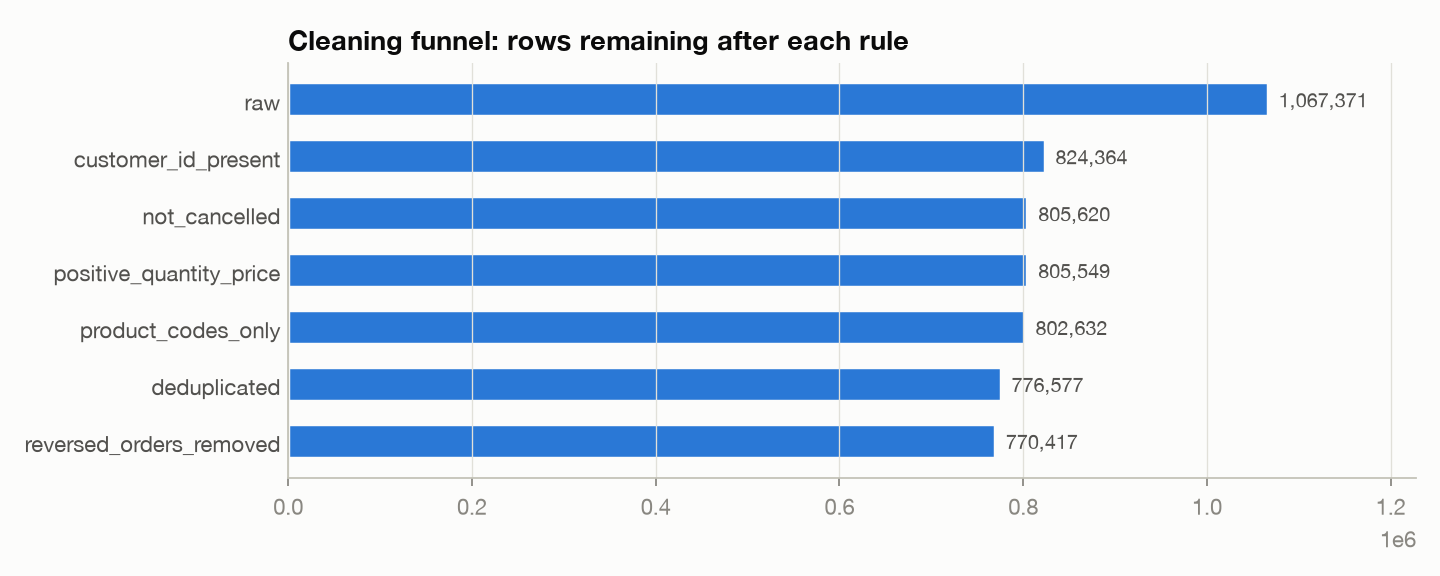

In [5]:
visualization._style()
visualization.data_quality()
display(Image(str(config.CHARTS_DIR / "00_data_quality_funnel.png")))

## 11. Exploratory data analysis (Spark SQL)

In [6]:
res = eda.run(spark, tx)
print(eda.QUERIES["monthly_revenue"])
res["kpis"].T


        SELECT InvoiceMonth, revenue, orders, customers,
               ROUND(SUM(revenue) OVER (ORDER BY InvoiceMonth
                     ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW), 2) AS cumulative_revenue
        FROM (SELECT InvoiceMonth, ROUND(SUM(Revenue), 2) AS revenue,
                     COUNT(DISTINCT Invoice) AS orders, COUNT(DISTINCT CustomerID) AS customers
              FROM tx GROUP BY InvoiceMonth)
        ORDER BY InvoiceMonth


,0
line_items,770417
orders,36333
customers,5839
products,4612
countries,41
revenue,16467402.7
avg_order_value,453.24
first_date,2009-12-01 07:45:00
last_date,2011-12-09 12:50:00


In [7]:
display(res["by_country"].head(10))
display(res["top_products_revenue"].head(10))
display(res["order_value_distribution"])

,Country,customers,orders,revenue
0,United Kingdom,5326,33140,13754301.24
1,EIRE,3,523,569548.58
2,Netherlands,22,214,546262.53
3,Germany,107,752,379977.15
4,France,93,587,294346.95
5,Australia,15,86,166769.80
6,Switzerland,22,79,92699.96
7,Spain,38,141,85092.83
8,Sweden,19,97,84249.74
9,Denmark,12,42,63478.19


,StockCode,Description,quantity,revenue
0,22423,REGENCY CAKESTAND 3 TIER,23427,269642.50
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,88451,238561.71
2,85099B,JUMBO BAG RED RETROSPOT,92528,166309.41
3,84879,ASSORTED COLOUR BIRD ORNAMENT,77784,123680.88
4,47566,PARTY BUNTING,23262,102425.08
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,27955,75504.43
6,79321,CHILLI LIGHTS,14737,68622.80
7,22386,JUMBO BAG PINK POLKADOT,36885,66958.72
8,48138,DOORMAT UNION FLAG,9857,64097.99
9,85099F,JUMBO BAG STRAWBERRY,35609,63713.49


,order_value_band,orders
0,1: <100,4342
1,2: 100-250,10882
2,3: 250-500,12835
3,4: 500-1k,5763
4,5: 1k-5k,2318
5,6: 5k+,193


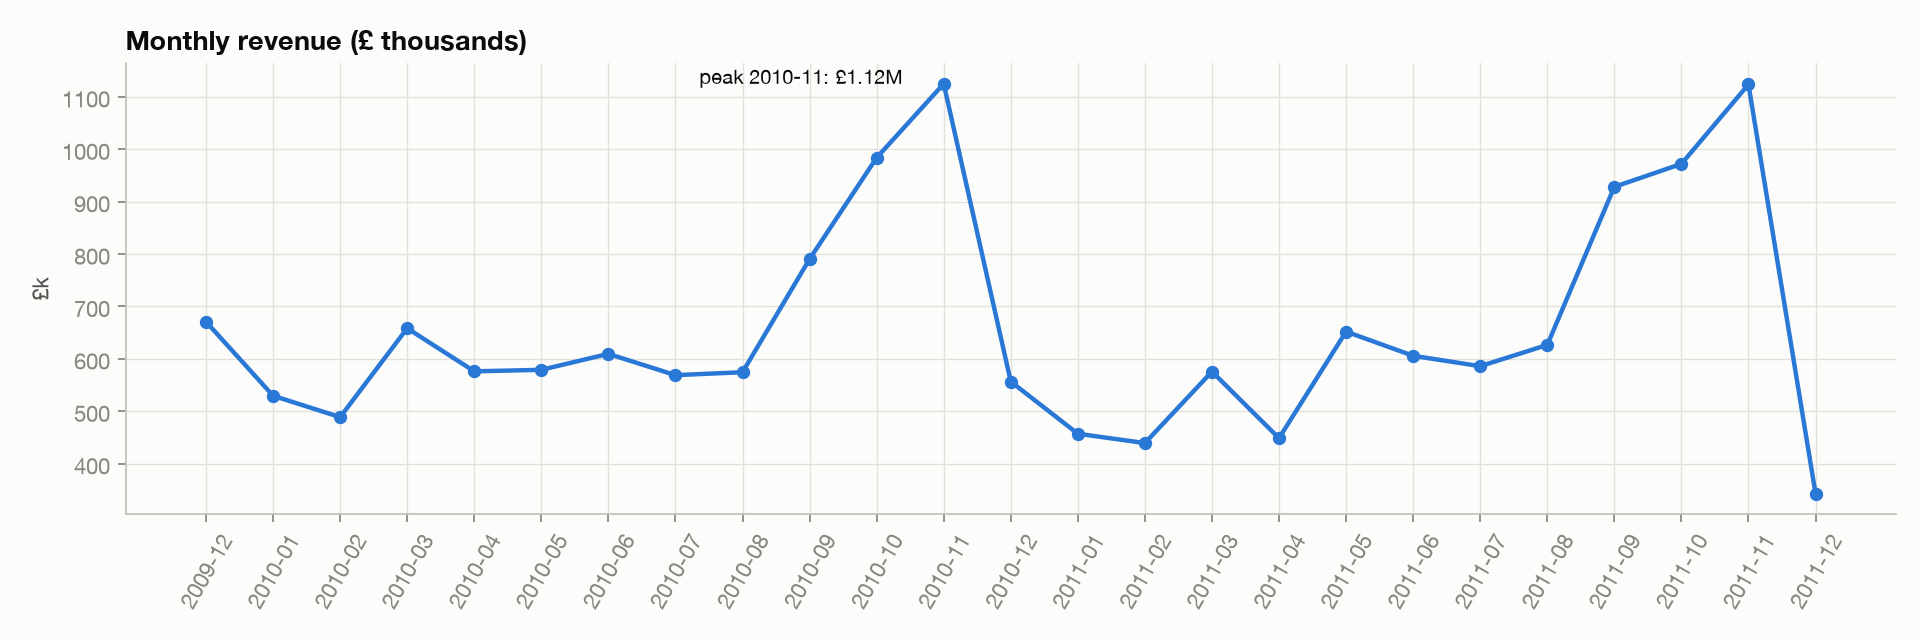

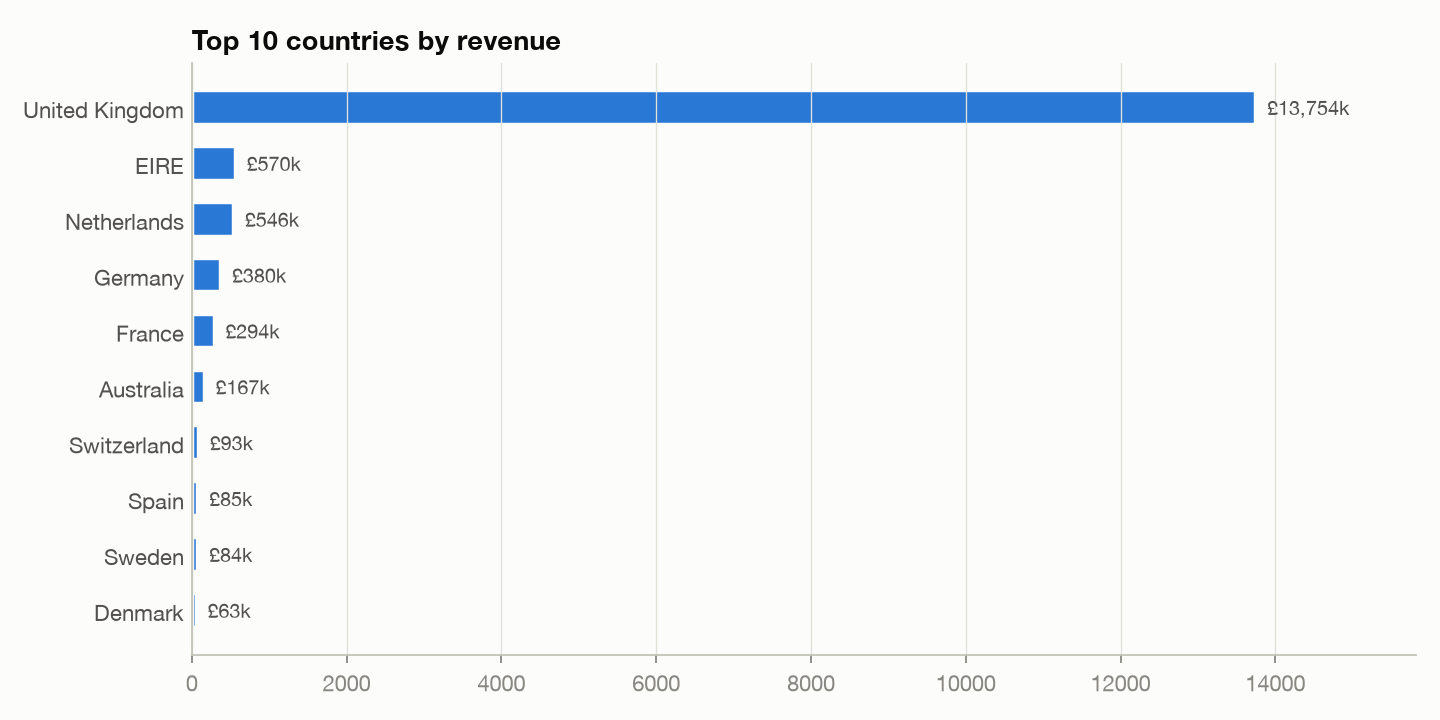

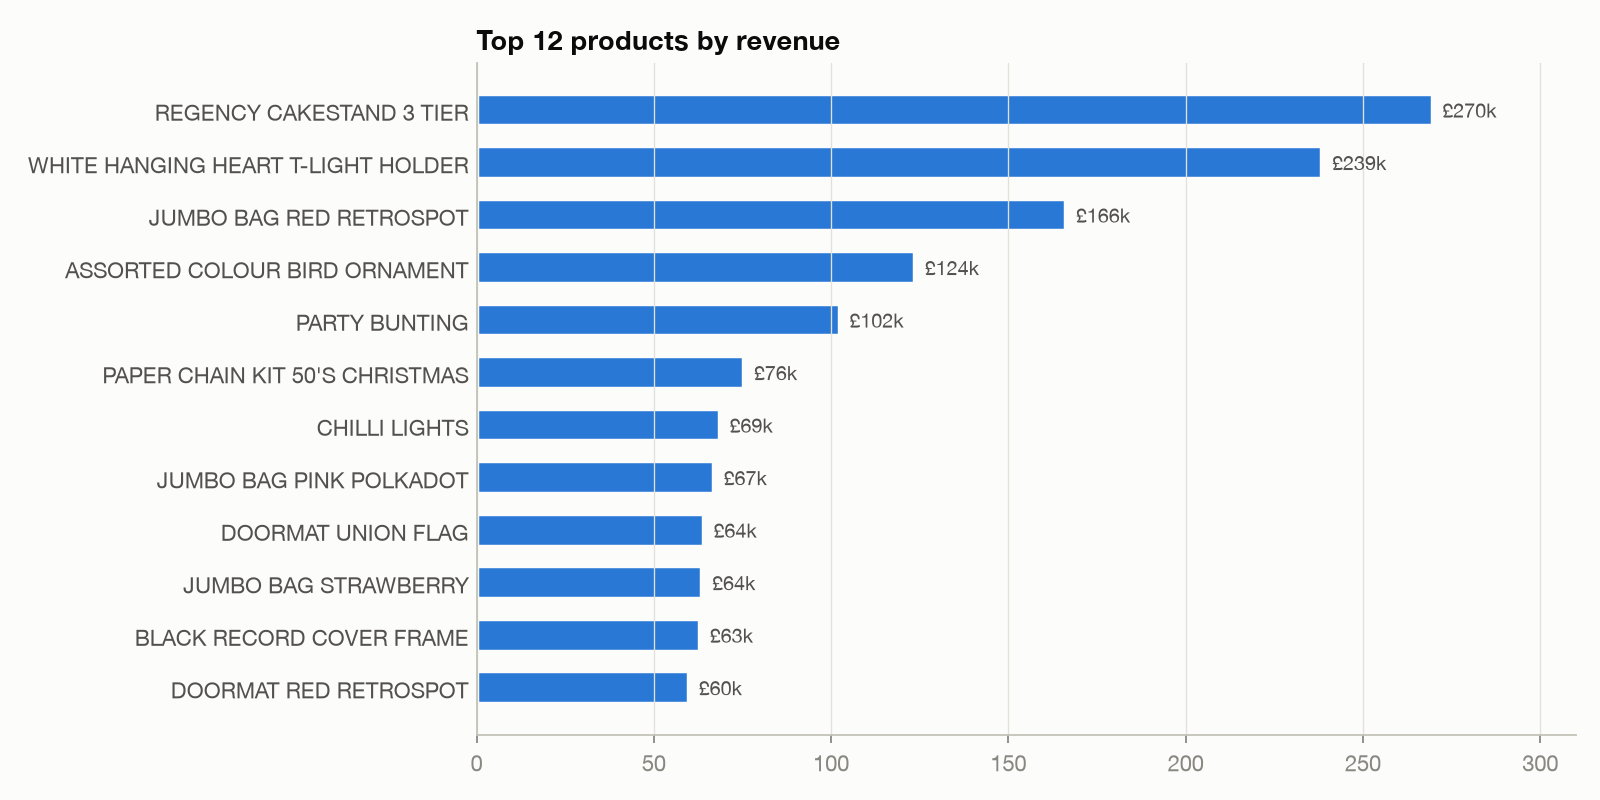

In [8]:
visualization.monthly_revenue(); visualization.top_lists()
for f in ["06_monthly_revenue.png", "07_top_countries.png", "08_top_products.png"]:
    display(Image(str(config.CHARTS_DIR / f)))

## 12–13. Revenue and customer analysis
`Revenue = Quantity × Price` is added during cleaning. Below is a long-tail check: what share of revenue comes from
the top 20% of customers?

In [9]:
cust_rev = tx.groupBy("CustomerID").agg(F.sum("Revenue").alias("rev")).toPandas().sort_values("rev", ascending=False)
top20 = cust_rev.head(int(len(cust_rev) * 0.2))["rev"].sum() / cust_rev["rev"].sum()
print(f"Top 20% of customers generate {top20:.1%} of revenue")

Top 20% of customers generate 76.6% of revenue


## 14. RFM + behavioural feature engineering
- **Reference date** = last invoice date + 1 day.
- **Recency** = days since the last purchase. **Frequency** = number of distinct invoices. **Monetary** = total
  revenue.
- The behavioural features are: average order value, total items, unique products, average quantity per order,
  active months, tenure, average days between orders (a `lag()` over `Window.partitionBy(CustomerID)`), and
  cancellation rate.

In [10]:
feats = features.run(spark, tx, cancelled).cache()
print(f"Customers: {feats.count():,}")
feats.select(*config.FEATURE_COLS).summary("min", "25%", "50%", "75%", "max").toPandas()

Customers: 5,839


,summary,Recency,Frequency,Monetary,AvgOrderValue,TotalItems,UniqueProducts,AvgQuantityPerOrder,ActiveMonths,TenureDays,AvgDaysBetweenOrders,CancellationRate
0,min,1,1,2.9,2.9,1,1,1.0,1,0,0.0,0.0
1,25%,26,1,336.08,174.95,188,19,91.5,1,0,39.2,0.0
2,50%,96,3,850.84,274.97,480,45,154.0,3,222,73.0,0.0
3,75%,380,7,2206.81,409.27,1344,103,258.33,6,512,131.6,0.2222
4,max,739,369,579128.64,12425.45,365112,2506,87167.0,25,738,714.0,0.8


## 15. Feature scaling
The RFM values are **heavily right-skewed**: a handful of wholesalers spend over £100k. K-Means uses Euclidean
distance, so we first apply `log1p` to the skewed features and then a `StandardScaler` (mean 0, standard deviation
1). Without this, a few outliers would form their own clusters.

In [11]:
prep_in = clustering.add_log_features(feats)
print("Model inputs:", clustering.model_input_cols())

Model inputs: ['log_Recency', 'log_Frequency', 'log_Monetary', 'log_AvgOrderValue', 'log_UniqueProducts', 'log_ActiveMonths', 'CancellationRate']


## 16–17. Choosing K and fitting K-Means
We sweep K from 2 to 8 and compute the **silhouette score** (cluster separation) and **WSSSE** (the elbow).
K is chosen as the best silhouette within the range that is actionable for the business (4–6 segments).

In [12]:
assigned, selection, sweep = clustering.run(feats)
display(sweep)
print(json.dumps(selection, indent=2))

  K-Means sweep:


    k=2: silhouette=0.5137 wssse=24995 groups=2 [Champions, Lost]


    k=3: silhouette=0.3797 wssse=20653 groups=3 [Champions, Loyal, Lost]


    k=4: silhouette=0.4073 wssse=17596 groups=3 [Champions, Loyal, Hibernating, Lost]


    k=5: silhouette=0.3587 wssse=15602 groups=4 [Champions, Loyal, At-Risk, Hibernating, Lost]


    k=6: silhouette=0.3381 wssse=14716 groups=4 [Champions, Loyal, Can't Lose Them, At-Risk, Hibernating, Lost]


    k=7: silhouette=0.3399 wssse=13702 groups=4 [Champions, Loyal, Loyal (II), At-Risk, Hibernating, Lost, Lost (III)]


    k=8: silhouette=0.3243 wssse=12769 groups=5 [Champions, Loyal, Can't Lose Them, At-Risk, Potential, Hibernating, Lost, Lost (III)]


,k,silhouette,wssse,min_cluster_size,segment_groups,segments
0,2,0.5137,24995.19,2487,2,"Champions, Lost"
1,3,0.3797,20652.77,1403,3,"Champions, Loyal, Lost"
2,4,0.4073,17596.36,895,3,"Champions, Loyal, Hibernating, Lost"
3,5,0.3587,15602.11,883,4,"Champions, Loyal, At-Risk, Hibernating, Lost"
4,6,0.3381,14716.34,449,4,"Champions, Loyal, Can't Lose Them, At-Risk, Hi..."
5,7,0.3399,13701.89,410,4,"Champions, Loyal, Loyal (II), At-Risk, Hiberna..."
6,8,0.3243,12769.17,432,5,"Champions, Loyal, Can't Lose Them, At-Risk, Po..."


{
  "chosen_k": 5,
  "chosen_silhouette": 0.3587,
  "chosen_segment_groups": 4,
  "best_overall_k": 2,
  "best_overall_silhouette": 0.5137,
  "reason": "k=5 gives the most distinct actionable segment groups (4: Champions, Loyal, At-Risk, Hibernating, Lost) within the business range 4-6, with silhouette 0.359. k=4 has a higher silhouette (0.407) but only 3 groups (Champions, Loyal, Hibernating, Lost). k=2 is the global silhouette maximum (0.514) but splits customers into too few groups to target differently.",
  "pca_explained_variance": [
    0.5797,
    0.1596
  ]
}


## 18. Customer segmentation: naming the clusters from their data

In [13]:
segmented, profile = profiling.run(spark, feats, assigned)
profile[["Cluster", "Segment", "Customers", "CustomerShare", "RevenueShare",
         "Recency_median", "Frequency_median", "Monetary_median", "relR", "relF", "relM"]]

,Cluster,Segment,Customers,CustomerShare,RevenueShare,Recency_median,Frequency_median,Monetary_median,relR,relF,relM
2,2,Champions,1026,0.1757,0.7180,18,14,5617.04,0.187500,4.666667,6.631140
4,0,Loyal,1521,0.2605,0.1531,41,5,1403.20,0.427083,1.666667,1.656534
0,3,At-Risk,883,0.1512,0.0635,236,3,853.88,2.458333,1.000000,1.008039
3,4,Hibernating,1354,0.2319,0.0540,318,1,469.19,3.312500,0.333333,0.553898
1,1,Lost,1055,0.1807,0.0115,337,1,155.80,3.510417,0.333333,0.183928


Segments are **not hard-coded**. Each cluster's median recency, frequency and monetary values are compared with
the median over all customers:
- **Recent, frequent and high-spend** clusters become Champions or Loyal.
- **Recent but not yet frequent** clusters become Potential.
- **Not recent but historically frequent or high-spend** clusters become At-Risk or Can't Lose Them.
- **Everything else** becomes Hibernating or Lost.

## 19. PCA visualisation

In [14]:
print("Explained variance (PC1, PC2):", selection["pca_explained_variance"])

Explained variance (PC1, PC2): [0.5797, 0.1596]


## 20. Segment analysis: value score, churn risk, product behaviour

**Customer Value Score**
- `CVS = 0.4 × M_pct + 0.3 × F_pct + 0.3 × R_pct`, where each percentile comes from `percent_rank()` over all
  customers. R is inverted so that recent buyers score high.
- Bands: Very High ≥ 80, High ≥ 60, Medium ≥ 40, Low ≥ 20, otherwise Very Low.

**Churn risk** compares inactivity with each customer's *own* buying rhythm:
`OverdueRatio = Recency / max(AvgDaysBetweenOrders, 30)`
- **High**: more than 90 days inactive, and either 2× overdue or high value (CVS ≥ 60).
- **Medium**: more than 90 days inactive, recency above the median, or 1.5× overdue.
- **Low**: everything else.

In [15]:
scored = scoring.run(segmented).cache()
scored.groupBy("Segment").pivot("ChurnRisk", ["Low", "Medium", "High"]).count().toPandas()

,Segment,Low,Medium,High
0,Lost,234,139,682
1,At-Risk,259,165,459
2,Hibernating,329,216,809
3,Loyal,1069,112,340
4,Champions,889,42,95


In [16]:
rules, rules_pdf, basket_meta = basket.run(spark, tx)
print(basket_meta)
rules_pdf[["AntecedentDesc", "ConsequentDesc", "support", "confidence", "lift"]].head(10)

    minSupport=0.02: 62 rules


    minSupport=0.015: 144 rules


{'baskets': 36333, 'min_support': 0.015, 'min_confidence': 0.2, 'rules': 144}


,AntecedentDesc,ConsequentDesc,support,confidence,lift
0,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0172,0.8380,32.5296
1,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.0172,0.6688,32.5296
2,TOILET METAL SIGN,BATHROOM METAL SIGN,0.0152,0.7621,29.9994
3,BATHROOM METAL SIGN,TOILET METAL SIGN,0.0152,0.5970,29.9994
4,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.0163,0.7952,27.3075
5,ROSES REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.0163,0.5614,27.3075
6,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.0204,0.7938,27.2602
7,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0204,0.7023,27.2602
8,BLUE 3 PIECE MINI DOTS CUTLERY SET,PINK 3 PIECE MINI DOTS CUTLERY SET,0.0170,0.7011,25.7577
9,PINK 3 PIECE MINI DOTS CUTLERY SET,BLUE 3 PIECE MINI DOTS CUTLERY SET,0.0170,0.6239,25.7577


In [17]:
favourite, pb = product_behaviour.run(tx, scored)
pb["top_products"].groupby("Segment").head(3)

,Segment,StockCode,Description,Quantity,Revenue,Buyers,Rank
0,At-Risk,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6305,16676.65,193,1
1,At-Risk,22423,REGENCY CAKESTAND 3 TIER,899,10958.25,185,2
2,At-Risk,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3774,7876.53,48,3
10,Champions,22423,REGENCY CAKESTAND 3 TIER,19071,217386.60,481,1
11,Champions,85123A,WHITE HANGING HEART T-LIGHT HOLDER,66313,178020.91,506,2
12,Champions,85099B,JUMBO BAG RED RETROSPOT,79074,141140.13,448,3
20,Hibernating,22423,REGENCY CAKESTAND 3 TIER,1039,12160.05,173,1
21,Hibernating,85123A,WHITE HANGING HEART T-LIGHT HOLDER,3069,8490.35,230,2
22,Hibernating,84879,ASSORTED COLOUR BIRD ORNAMENT,3600,5815.20,151,3
30,Lost,85123A,WHITE HANGING HEART T-LIGHT HOLDER,926,2565.30,88,1


## 21. Recommendation engine

In [18]:
display(recommender.rules_table())
names = basket.product_names(tx)
final = recommender.run(scored, tx, rules, names, favourite)
ci = save_final(final)
final.select("CustomerID", "Segment", "ValueBand", "ChurnRisk", "Priority", "RecommendedAction",
             "RecommendedProducts").orderBy("Priority", F.desc("CVS")).show(10, truncate=60)

,RuleId,Action,Channel,Offer,Priority
0,R1-VALUABLE-SLIPPING,Personal win-back: account-manager outreach + ...,Email + Phone,15% win-back voucher,P1
1,R2-CHAMPION-ACTIVE,"VIP loyalty: early access to new ranges, free ...",Email + Loyalty programme,VIP perks (no discount),P2
2,R3-CHAMPION-COOLING,VIP check-in: personalised thank-you + exclusi...,Email,Exclusive bundle,P1
3,R4-LOYAL,Membership / points programme + cross-sell fro...,Email + On-site recommendations,Double loyalty points,P2
4,R5-POTENTIAL-ACTIVE,Nurture: cross-sell recommended products + sec...,Email + On-site recommendations,10% off next order,P3
5,R6-POTENTIAL-SLIPPING,Early re-activation: reminder of favourite cat...,Email + Retargeting ads,Free shipping,P2
6,R7-AT-RISK,Win-back campaign: 'We miss you' message with ...,Email + Retargeting ads,10% discount,P2
7,R8-LOST-WORTH-TRYING,Re-engagement: seasonal catalogue + comeback o...,Email,20% comeback offer,P3
8,R9-LOST,"Low-cost re-engagement: newsletter only, exclu...",Newsletter,None,P4
9,R0-DEFAULT,Standard newsletter,Newsletter,None,P4


+----------+---------+---------+---------+--------+------------------------------------------------------------+------------------------------------------------------------+
|CustomerID|  Segment|ValueBand|ChurnRisk|Priority|                                           RecommendedAction|                                         RecommendedProducts|
+----------+---------+---------+---------+--------+------------------------------------------------------------+------------------------------------------------------------+
|     16019|Champions|Very High|   Medium|      P1|VIP check-in: personalised thank-you + exclusive bundle b...|WOOD 2 DRAWER CABINET WHITE FINISH | JUMBO BAG PINK VINTA...|
|     14952|Champions|Very High|   Medium|      P1|VIP check-in: personalised thank-you + exclusive bundle b...|TOILET METAL SIGN | CHARLOTTE BAG PINK POLKADOT | STRAWBE...|
|     12939|Champions|Very High|   Medium|      P1|VIP check-in: personalised thank-you + exclusive bundle b...|JUMBO BAG SCANDINA

## 22. Results and business insights

In [19]:
summary = (ci.groupby("Segment")
             .agg(Customers=("CustomerID", "count"), Revenue=("Monetary", "sum"),
                  MedianRecency=("Recency", "median"), MedianOrders=("Frequency", "median"),
                  AvgCVS=("CVS", "mean"), HighRisk=("ChurnRisk", lambda s: (s == "High").mean()))
             .sort_values("Revenue", ascending=False))
summary["RevenueShare"] = summary["Revenue"] / summary["Revenue"].sum()
summary.round(3)

,Customers,Revenue,MedianRecency,MedianOrders,AvgCVS,HighRisk,RevenueShare
Segment,,,,,,,
Champions,1026,11823780.66,18.0,14.0,85.805,0.093,0.718
Loyal,1521,2520453.18,41.0,5.0,63.324,0.224,0.153
At-Risk,883,1044888.31,236.0,3.0,41.422,0.520,0.063
Hibernating,1354,889572.17,318.5,1.0,29.616,0.597,0.054
Lost,1055,188708.38,337.0,1.0,17.900,0.646,0.011


  charts -> /Users/rohit/Desktop/BDA project/outputs/charts


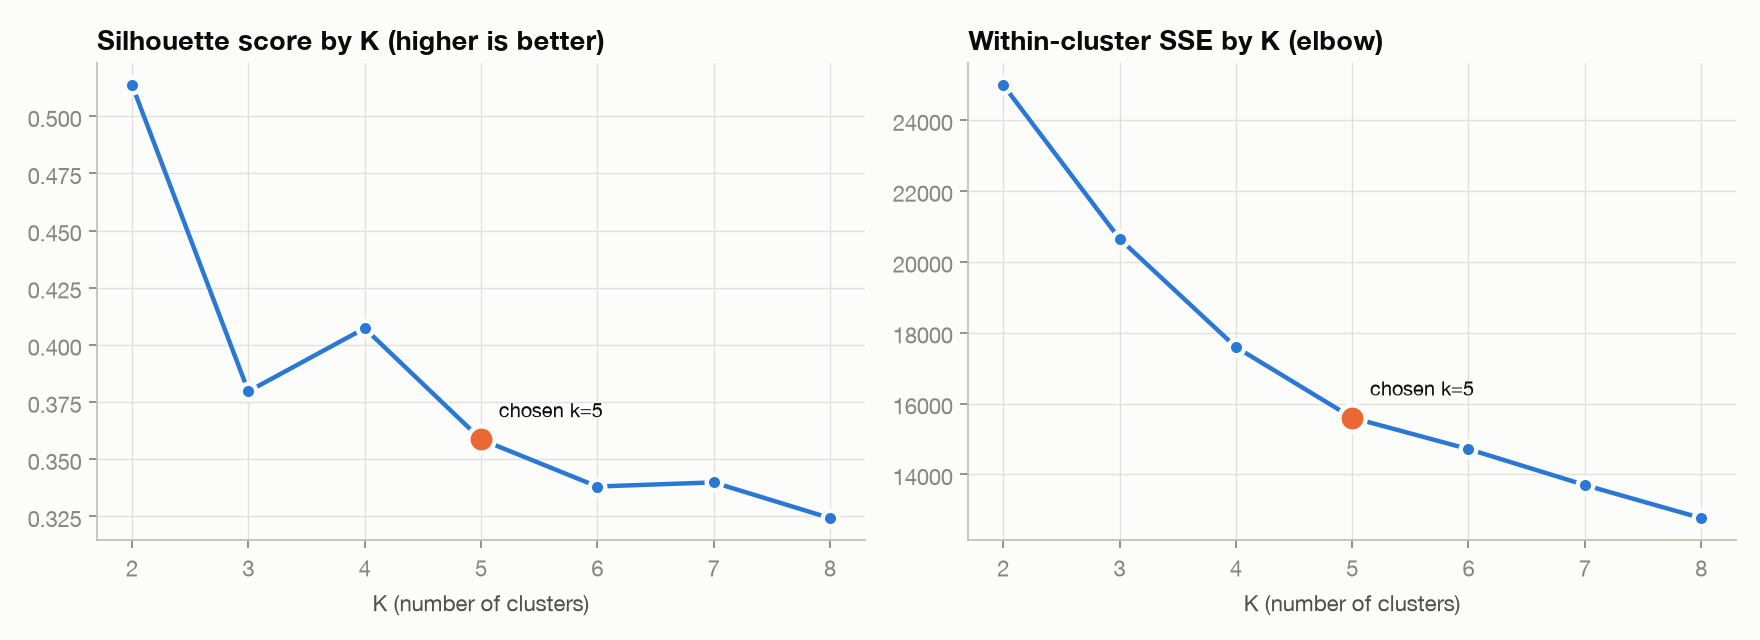

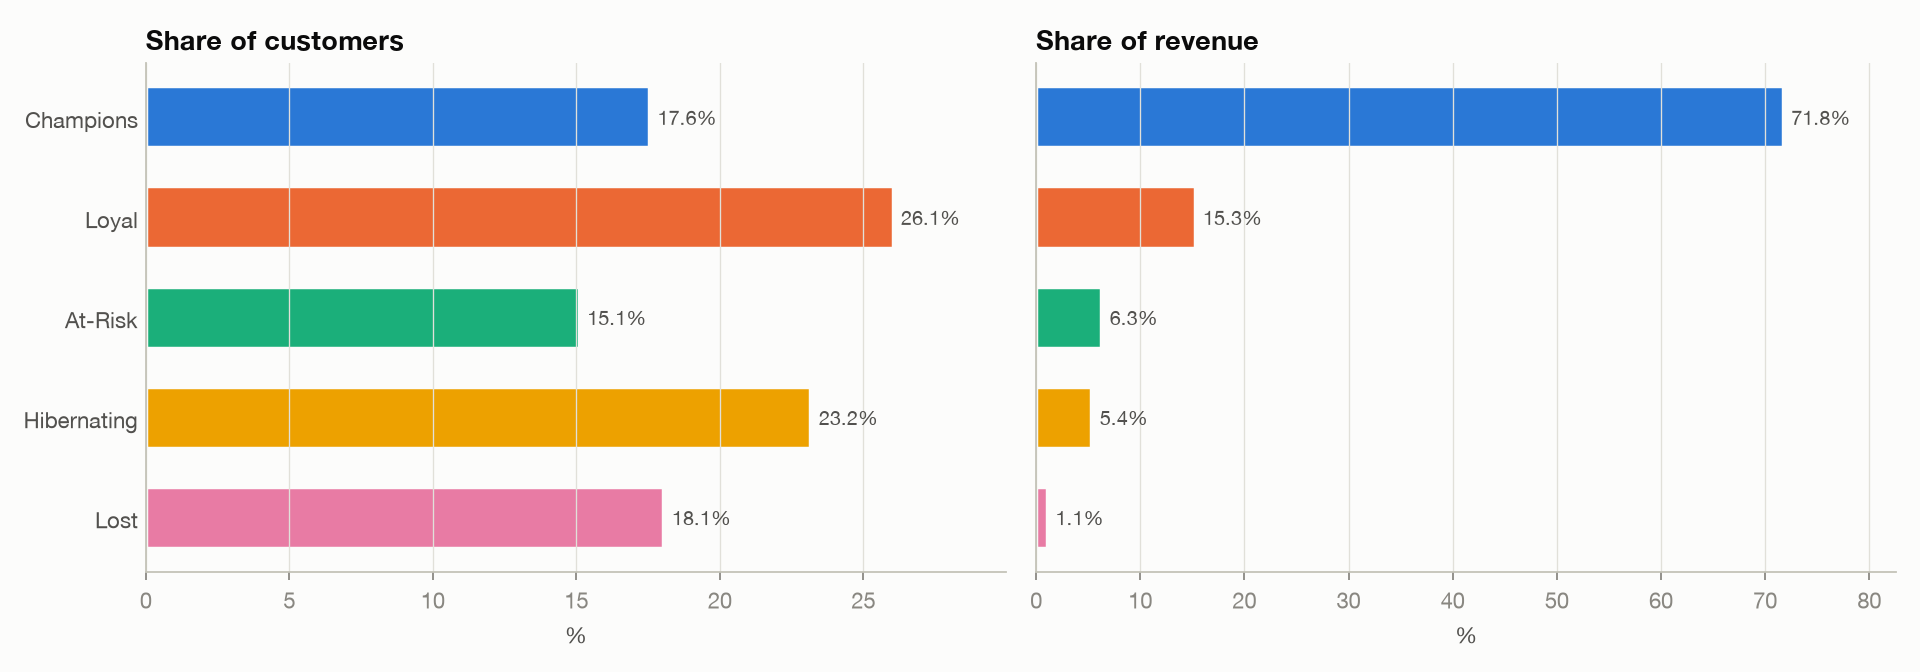

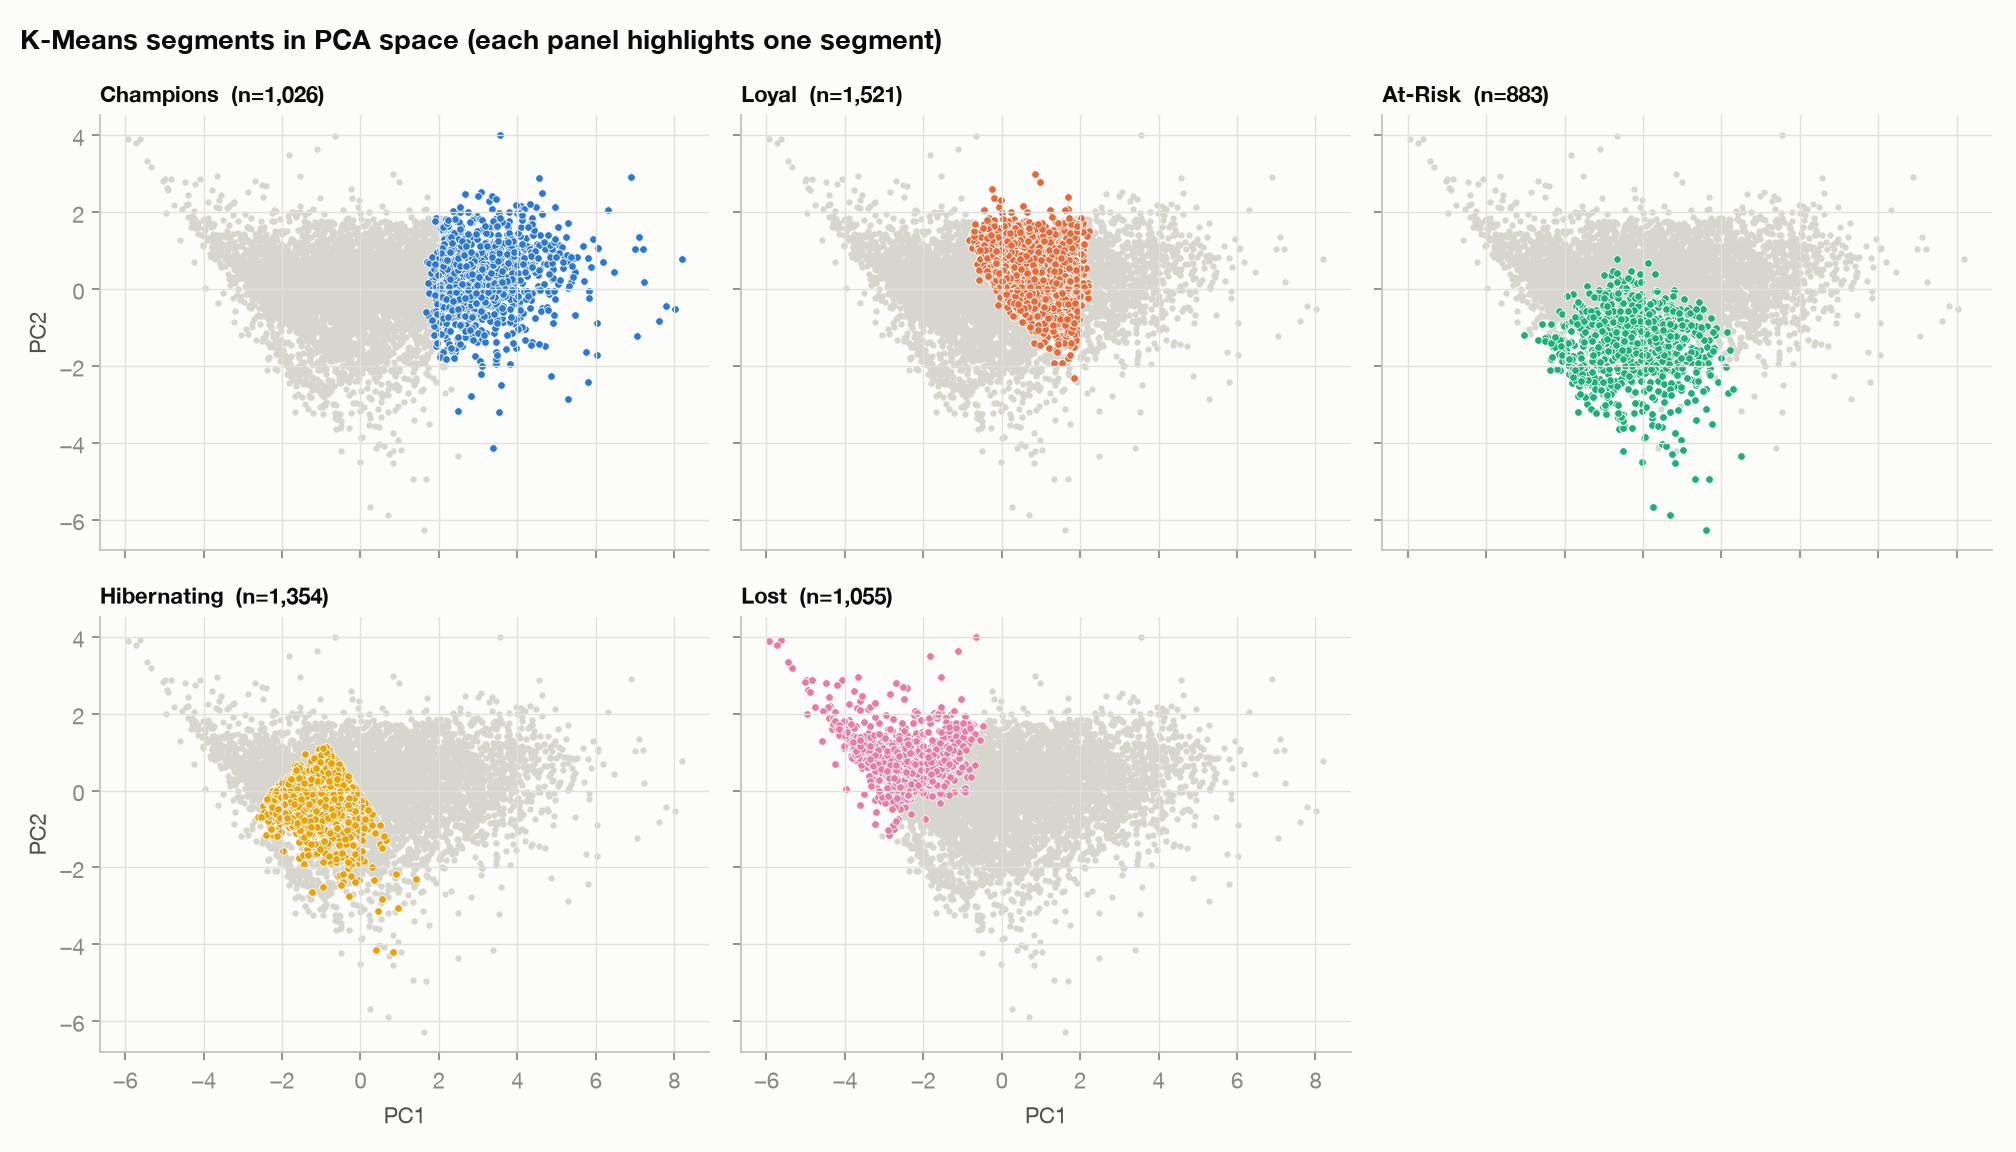

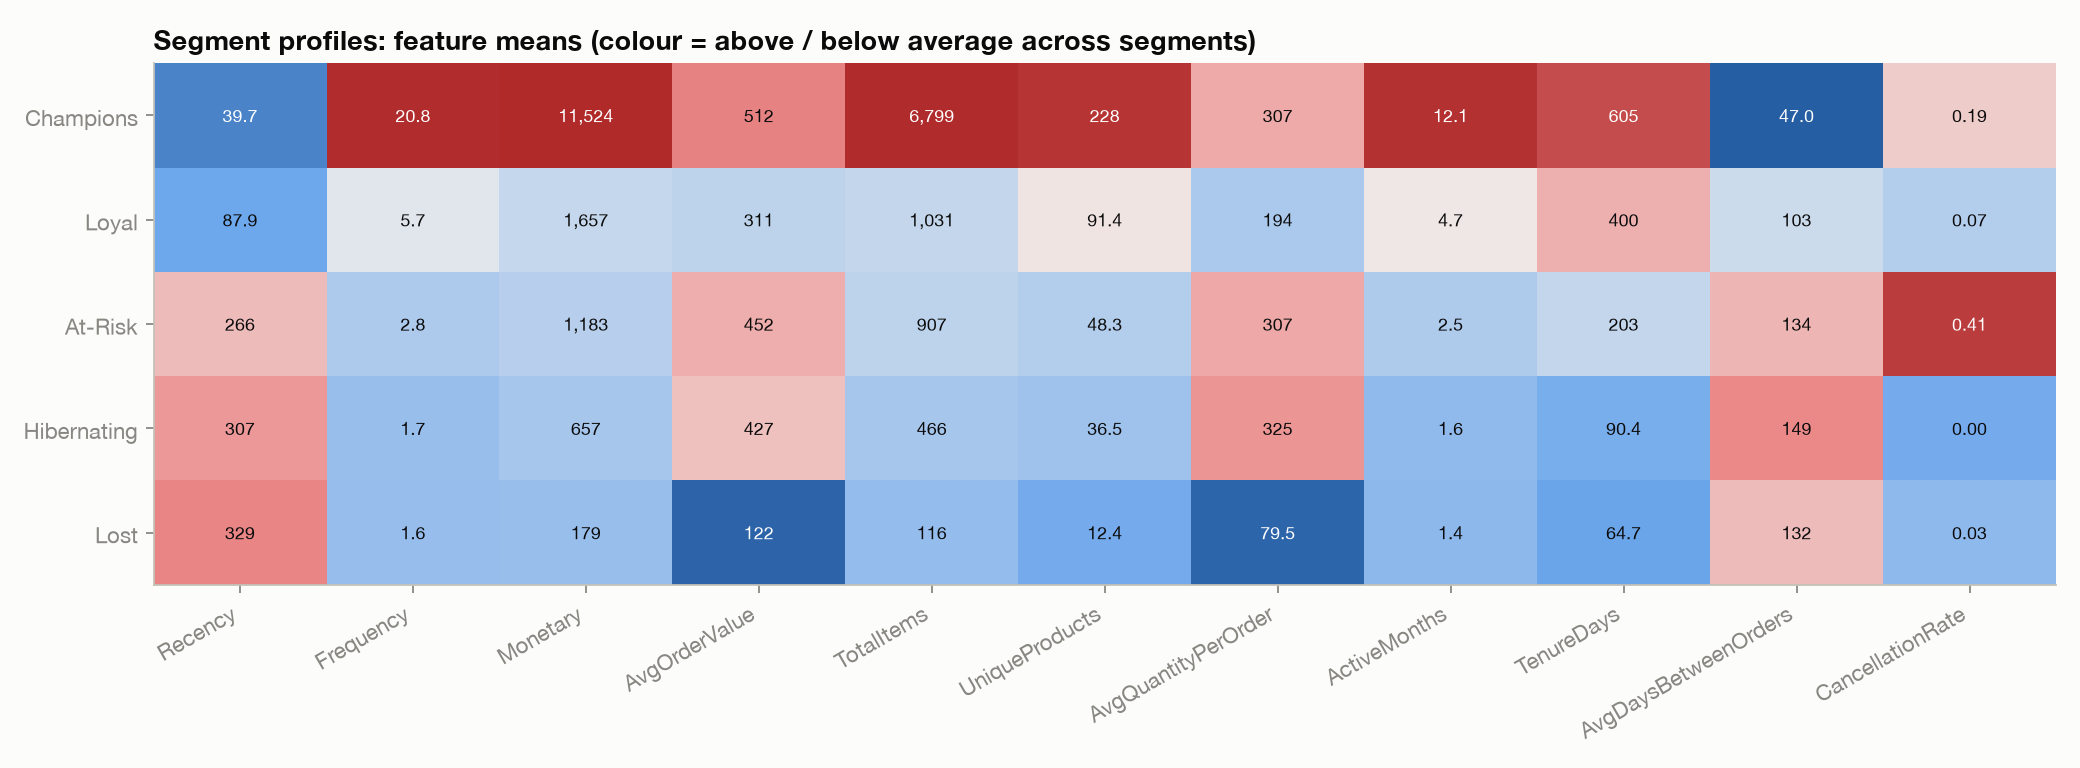

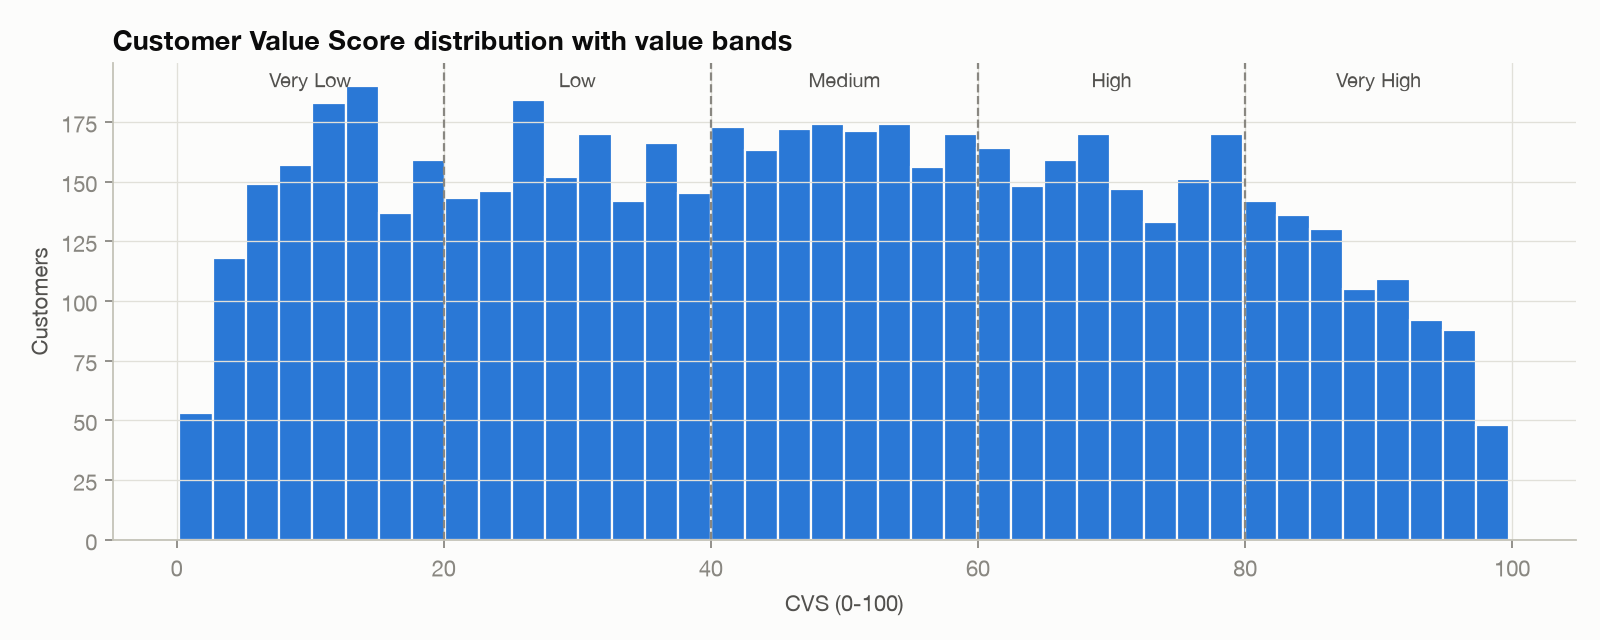

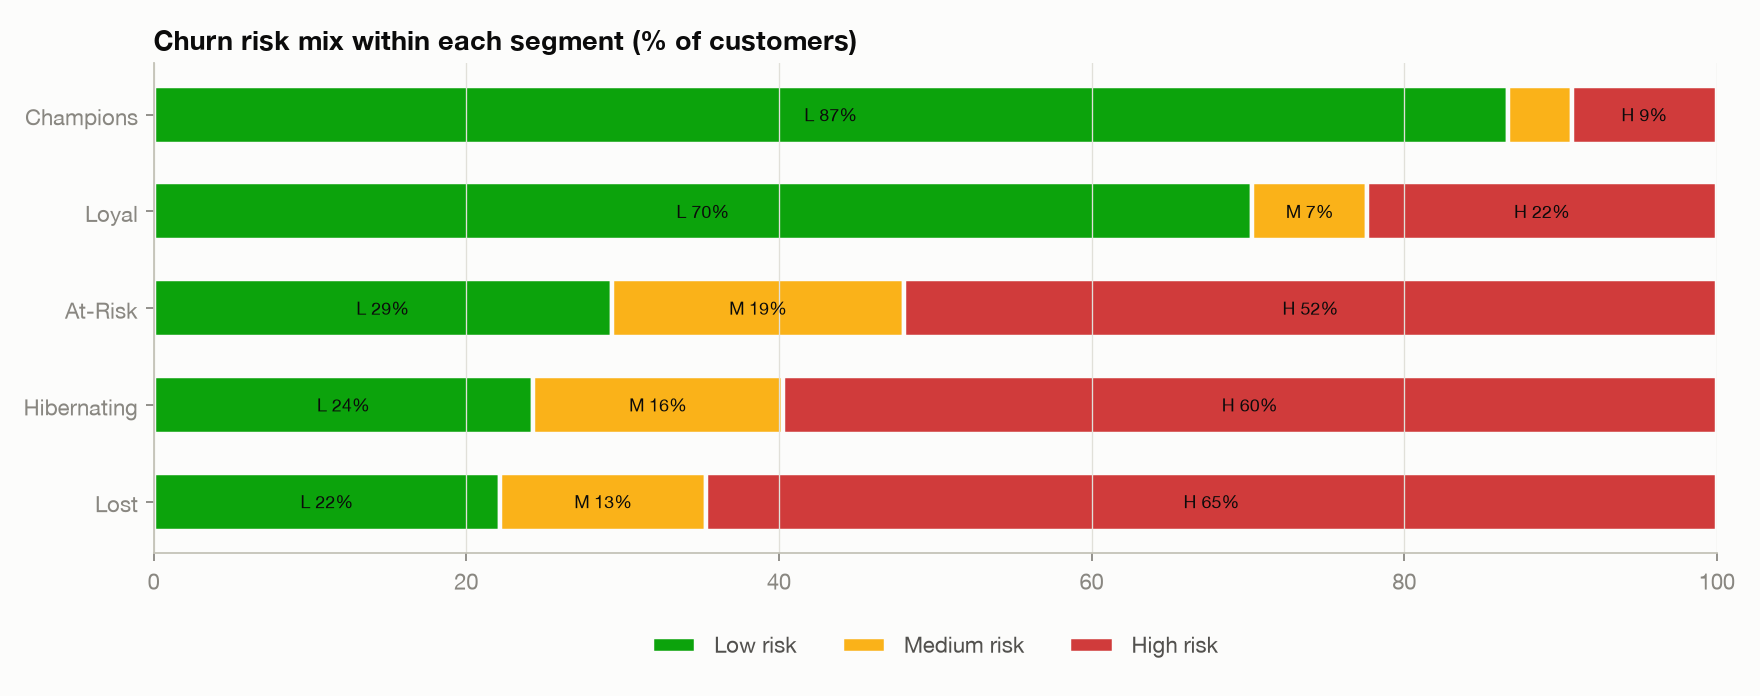

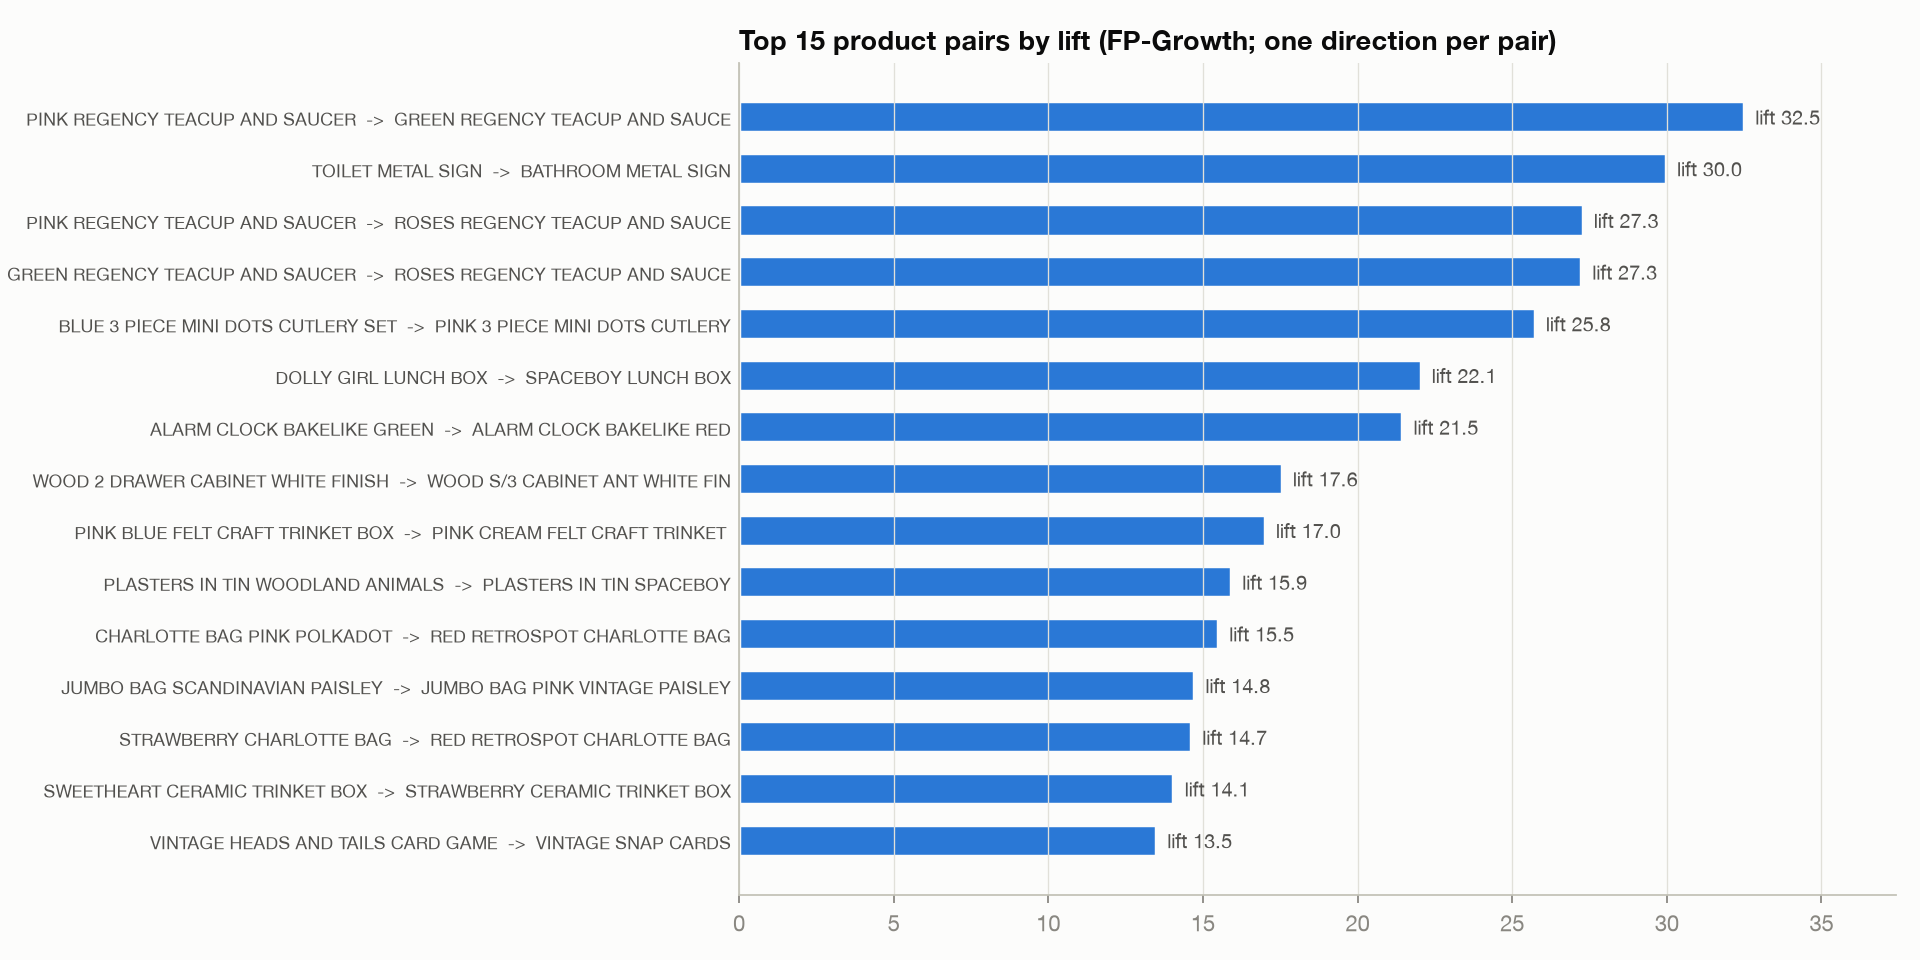

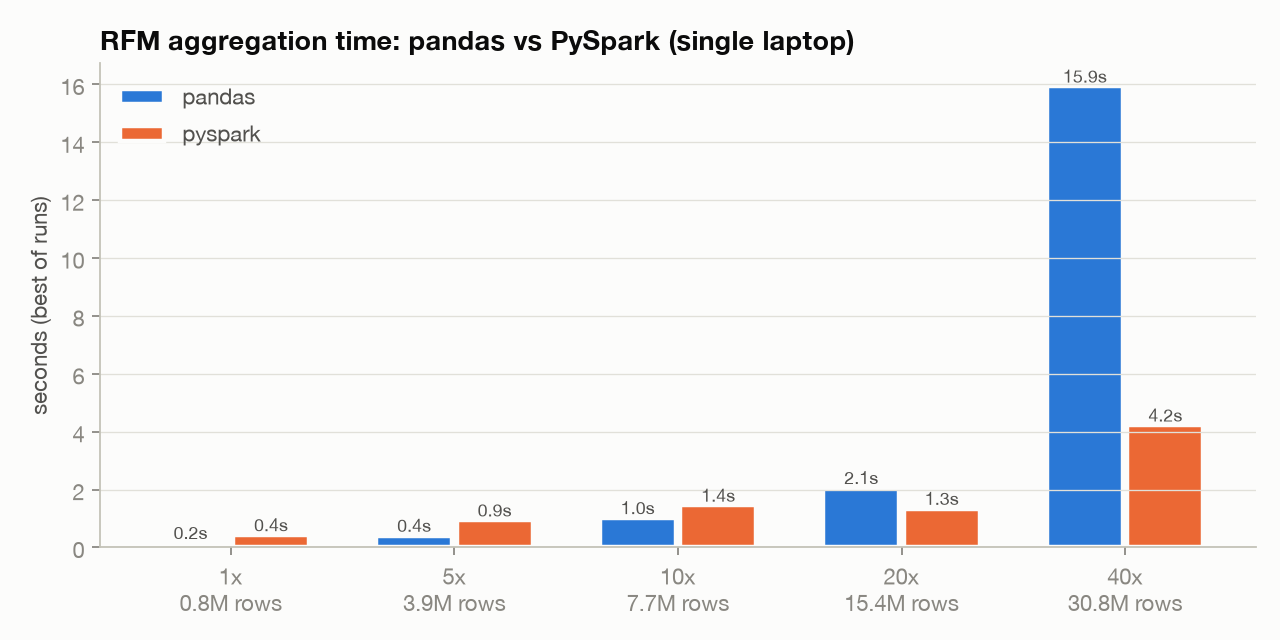

In [20]:
visualization.make_all()   # regenerate every chart from this run's outputs
for f in ["01_k_selection.png", "02_segment_size_vs_revenue.png", "03_pca_segments.png",
          "05_segment_profile_heatmap.png", "09_cvs_distribution.png", "10_churn_risk_by_segment.png",
          "11_top_association_rules.png", "12_benchmark.png"]:
    p = config.CHARTS_DIR / f
    if p.exists():
        display(Image(str(p)))

## 23. Conclusion
The pipeline turns about 1M raw transactions into a ranked, per-customer action list:
- a segment
- a value score
- a churn risk
- a prioritised marketing action
- cross-sell products mined with FP-Growth

All of it is computed with Spark DataFrames, Spark SQL and MLlib, so the same code scales from a laptop
(`local[*]`) to a cluster just by changing the Spark master.

**Future scope:**
- streaming ingestion with Structured Streaming
- a supervised churn model once labelled outcomes exist
- product-category enrichment
- A/B testing the recommended campaigns

In [21]:
spark.stop()